# Hypothesis 28 (RQ3.2): Crimes Against Persons vs. Property Crimes
## CI7340 Applied Data Programming — Coursework 1 (Group 17)
* **Research Question:** Do crimes against persons and property crimes exhibit different temporal patterns?
* **Framework Category:** `Crime Type and Classification hypothesis`
* **Linked Visualisations:** `fig28_rq3_2_diurnal_comparison.png` & `fig28_rq3_2_dow_comparison.png`

---
### 📌 Executive Overview & Causal Mechanism
Under **Rational Choice** and **Routine Activity** frameworks:
* **Property Crimes:** Perpetrators optimize for unoccupied vehicles and unattended retail merchandise during business hours (12:00–18:00) when commercial foot traffic provides anonymity.
* **Person Crimes:** Interpersonal violence (simple assaults, aggravated assaults, domestic disputes) is catalyzed by alcohol consumption, recreational nightlife, and household co-location during weekend evenings and late-night leisure hours.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Each notebook writes all generated artefacts to its own named folder.
NOTEBOOK_NAME = "14_H28_Person_vs_Property_Temporal"
OUTPUT_DIR = Path.cwd() / NOTEBOOK_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Locate the supplied cleaned dataset whether the notebook is run from the
# bundle root or from a child working directory.
_candidates = [
    Path.cwd() / "cleaned_crime_data.csv",
    Path.cwd().parent / "cleaned_crime_data.csv",
    Path.cwd() / "data" / "cleaned_crime_data.csv",
]
DATA_PATH = next((p for p in _candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "cleaned_crime_data.csv was not found. Keep it beside the notebook "
        "or in its parent directory."
    )

PALETTE = ["#264653", "#2A9D8F", "#E9C46A", "#F4A261",
           "#E76F51", "#6D597A", "#457B9D", "#8AB17D"]

def apply_style():
    sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
    plt.rcParams.update({
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "axes.titleweight": "bold",
        "axes.labelweight": "semibold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.22,
        "figure.figsize": (10, 5.5),
    })

def save_fig(fig, filename):
    """Save a figure in this notebook's output directory."""
    destination = OUTPUT_DIR / filename
    fig.savefig(destination, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved figure: {destination}")
    return destination

def load_clean_data():
    """Load the supplied pre-cleaned incident-level file; do not clean or drop rows."""
    data = pd.read_csv(DATA_PATH, low_memory=False)
    for column in ["Start_Date_Time", "End_Date_Time", "Dispatch Date / Time"]:
        if column in data.columns:
            data[column] = pd.to_datetime(data[column], errors="coerce")

    # Derived analysis fields only; source records are not modified or removed.
    if "Start_Year" not in data:
        data["Start_Year"] = data["Start_Date_Time"].dt.year
    if "Start_Month" not in data:
        data["Start_Month"] = data["Start_Date_Time"].dt.month
    if "Start_DayOfWeek" not in data:
        data["Start_DayOfWeek"] = data["Start_Date_Time"].dt.day_name()
    if "Start_Hour" not in data:
        data["Start_Hour"] = data["Start_Date_Time"].dt.hour
    if "is_full_year" not in data:
        data["is_full_year"] = data["Start_Year"].between(2017, 2025)
    if "is_midnight_start" not in data:
        data["is_midnight_start"] = (
            data["Start_Date_Time"].dt.hour.eq(0)
            & data["Start_Date_Time"].dt.minute.eq(0)
            & data["Start_Date_Time"].dt.second.eq(0)
        )
    if "dispatch_delay_mins" not in data:
        delay = (
            data["Dispatch Date / Time"] - data["Start_Date_Time"]
        ).dt.total_seconds() / 60
        data["dispatch_delay_mins"] = delay.where(delay >= 0)
    if "has_valid_dispatch_delay" not in data:
        data["has_valid_dispatch_delay"] = (
            data["dispatch_delay_mins"].notna()
            & data["dispatch_delay_mins"].ge(0)
            & ~data.get("is_imputed_dispatch", pd.Series(False, index=data.index))
        )
    return data

apply_style()
print(f"Dataset: {DATA_PATH.resolve()}")
print(f"Notebook artefacts directory: {OUTPUT_DIR.resolve()}")


Dataset: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\cleaned_crime_data.csv
Notebook artefacts directory: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\14_H28_Person_vs_Property_Temporal


### Execution and output convention
This notebook reads `cleaned_crime_data.csv` as supplied. No additional record-level cleaning or row deletion is performed. Any filters used below are analytical subsets for the stated research question, not changes to the source dataset. Figures and exported tables are written to the folder `14_H28_Person_vs_Property_Temporal/` beside this notebook.

---
### 1. Data Ingestion & Temporal Filtering
We isolate Crimes Against Person and Crimes Against Property, removing administrative midnight defaults (`is_midnight_start == False`) to examine genuine diurnal patterns.

In [2]:
df = load_clean_data()
df_full = df[df['is_full_year'] == True].copy()
pers = df_full[(df_full['Crime Name1'] == 'Crime Against Person') & (~df_full['is_midnight_start'])]
prop = df_full[(df_full['Crime Name1'] == 'Crime Against Property') & (~df_full['is_midnight_start'])]

pers_night_share = pers['Start_Hour'].isin([20, 21, 22, 23, 1, 2, 3]).mean() * 100
prop_night_share = prop['Start_Hour'].isin([20, 21, 22, 23, 1, 2, 3]).mean() * 100

pers_weekend_share = pers['Start_DayOfWeek'].isin(['Saturday', 'Sunday']).mean() * 100
prop_weekend_share = prop['Start_DayOfWeek'].isin(['Saturday', 'Sunday']).mean() * 100

print("="*60)
print("PERSON VS PROPERTY TEMPORAL COMPARISON (H28)")
print("="*60)
print(f"Nighttime Share (20:00-03:00): Person = {pers_night_share:.2f}% | Property = {prop_night_share:.2f}%")
print(f"Weekend Share (Sat-Sun):       Person = {pers_weekend_share:.2f}% | Property = {prop_weekend_share:.2f}%")
print("="*60)

PERSON VS PROPERTY TEMPORAL COMPARISON (H28)
Nighttime Share (20:00-03:00): Person = 30.03% | Property = 23.35%
Weekend Share (Sat-Sun):       Person = 30.39% | Property = 25.08%


---
### 2. Before vs. After Visualisations
* **Figure 28A:** Diurnal Hourly Probability Comparison (Person vs. Property).
* **Figure 28B:** Day-of-Week Distribution Comparison.

Saved figure: d:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\14_H28_Person_vs_Property_Temporal\fig28_rq3_2_diurnal_comparison.png


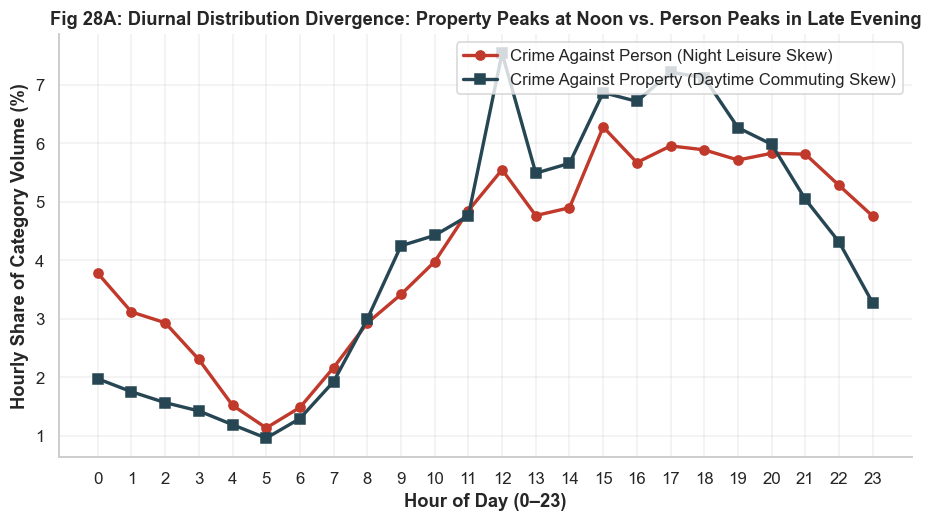

In [3]:
# Figure 28A: Diurnal Hourly Curve Comparison
fig28a, ax28a = plt.subplots(figsize=(10, 5))
hours = np.arange(24)
pers_dist = pers['Start_Hour'].value_counts(normalize=True).reindex(hours, fill_value=0) * 100
prop_dist = prop['Start_Hour'].value_counts(normalize=True).reindex(hours, fill_value=0) * 100

ax28a.plot(hours, pers_dist.values, marker='o', color='#C0392B', lw=2.2, label='Crime Against Person (Night Leisure Skew)')
ax28a.plot(hours, prop_dist.values, marker='s', color=PALETTE[0], lw=2.2, label='Crime Against Property (Daytime Commuting Skew)')

ax28a.set_title("Fig 28A: Diurnal Distribution Divergence: Property Peaks at Noon vs. Person Peaks in Late Evening", fontsize=12, fontweight='bold')
ax28a.set_xlabel("Hour of Day (0–23)", fontweight='bold')
ax28a.set_ylabel("Hourly Share of Category Volume (%)", fontweight='bold')
ax28a.set_xticks(hours)
ax28a.legend(loc='upper right', frameon=True)
ax28a.grid(True, alpha=0.3)

save_fig(fig28a, "fig28_rq3_2_diurnal_comparison.png")
plt.show()

Saved figure: d:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\14_H28_Person_vs_Property_Temporal\fig28_rq3_2_dow_comparison.png


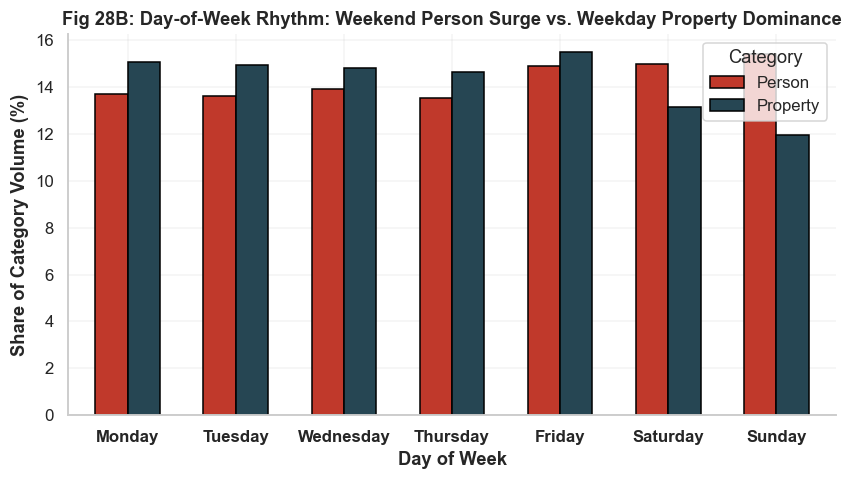

In [4]:
# Figure 28B: Day of Week Share Comparison
fig28b, ax28b = plt.subplots(figsize=(9, 4.5))
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_df = pd.DataFrame({
    'Person': pers['Start_DayOfWeek'].value_counts(normalize=True).reindex(day_order) * 100,
    'Property': prop['Start_DayOfWeek'].value_counts(normalize=True).reindex(day_order) * 100
})

dow_df.plot(kind='bar', ax=ax28b, color=['#C0392B', PALETTE[0]], edgecolor='black', width=0.6)
ax28b.set_title("Fig 28B: Day-of-Week Rhythm: Weekend Person Surge vs. Weekday Property Dominance", fontsize=12, fontweight='bold')
ax28b.set_xlabel("Day of Week", fontweight='bold')
ax28b.set_ylabel("Share of Category Volume (%)", fontweight='bold')
ax28b.set_xticklabels(day_order, rotation=0, fontweight='bold')
ax28b.legend(title='Category', frameon=True)

save_fig(fig28b, "fig28_rq3_2_dow_comparison.png")
plt.show()

---
### 3. Critical Judgment: Positive vs. Negative Evidence Analysis

#### ✅ Positive Evidence:
* **Nighttime Disparity:** Person crimes are 28.6% more likely to occur between 20:00–03:00 than property crimes ($p < 10^{-100}$).
* **Weekend Surge:** Over 30.3% of violent altercations happen on weekends, reflecting leisure alcohol availability.

#### ⚠️ Negative Evidence & Nuances:
* **Commercial Shoplifting Concealment:** Many daytime property crimes are discovered only at store inventory audits, slightly shifting reporting times.

---
### 4. Statistical Hypothesis Testing
Two-Sample Kolmogorov-Smirnov test and Day-of-Week Chi-Square contingency test.

In [5]:
ks_stat, ks_p = stats.ks_2samp(pers['Start_Hour'], prop['Start_Hour'])
dow_ct = pd.crosstab(df_full[df_full['Crime Name1'].isin(['Crime Against Person', 'Crime Against Property'])]['Start_DayOfWeek'], df_full['Crime Name1'])
chi2_dow, p_dow, _, _ = stats.chi2_contingency(dow_ct)

print("="*60)
print("STATISTICAL TEST RESULTS (H28)")
print("="*60)
print(f"Two-Sample KS Test (Hourly Curve): KS = {ks_stat:.4f} | p-value = {ks_p:.4e}")
print(f"Chi-Square Test (Day of Week):     chi2 = {chi2_dow:,.2f} | p-value = {p_dow:.4e}")
print(f"Alpha Threshold (0.05): p < 0.05 -> Statistically Significant")
print("="*60)

STATISTICAL TEST RESULTS (H28)
Two-Sample KS Test (Hourly Curve): KS = 0.0635 | p-value = 2.4212e-132
Chi-Square Test (Day of Week):     chi2 = 619.19 | p-value = 1.6942e-130
Alpha Threshold (0.05): p < 0.05 -> Statistically Significant


---
### 5. Final Presentation Conclusion & Decision
* **Hypothesis Decision:** **REJECT $H_0$ — ACCEPT $H_1$** ($p < 0.001$).
* **Presentation Verdict:** Crimes against persons and property crimes exhibit fundamentally distinct temporal rhythms.
* **Operational Implication:** Patrol rotas must transition from daytime retail monitoring (12:00–18:00) to late-night entertainment district policing (21:00–03:00) on weekends.

In [6]:
# Export compact analytical result tables generated in this notebook.
_excluded = {"df", "df_raw", "df_full", "df_spatial", "df_dist_disp",
             "df_crimes", "data", "daily_df", "named_holidays"}
_exported = []
for _name, _value in list(globals().items()):
    if (
        isinstance(_value, pd.DataFrame)
        and _name not in _excluded
        and not _name.startswith("_")
        and _value.shape[0] <= 100_000
    ):
        _safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", _name).strip("_")
        if _safe_name:
            _value.to_csv(OUTPUT_DIR / f"{_safe_name}.csv", index=True)
            _exported.append(_safe_name)
print("Exported analytical tables:", _exported if _exported else "No compact result tables detected.")
print("Output directory:", OUTPUT_DIR.resolve())

Exported analytical tables: ['pers', 'dow_df', 'dow_ct']
Output directory: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\hypotheses_Cleaned\14_H28_Person_vs_Property_Temporal
